# Self-Organizing Maps (SOM)
## TC2035 - Diseño de Redes Neuronales y Aprendizaje Profundo
### *A00838589 - Steffany Mishell Lara Muy*

Esta actividad tiene como objetivo principal aplicar el conocimiento de redes neuronales en el contexto de aprendizaje competitivo, equivalente al supervised learning en la Inteligencia Artifical normal.

Se tomará como base el tutorial brindado por el maestro con modificaciones en parámetros de sintonización, medidas de distancia el pase múltiples.



<>:17: SyntaxWarning: invalid escape sequence '\e'
<>:17: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipython-input-3554207116.py:17: SyntaxWarning: invalid escape sequence '\e'
  plt.ylabel('$\eta^(t)$')


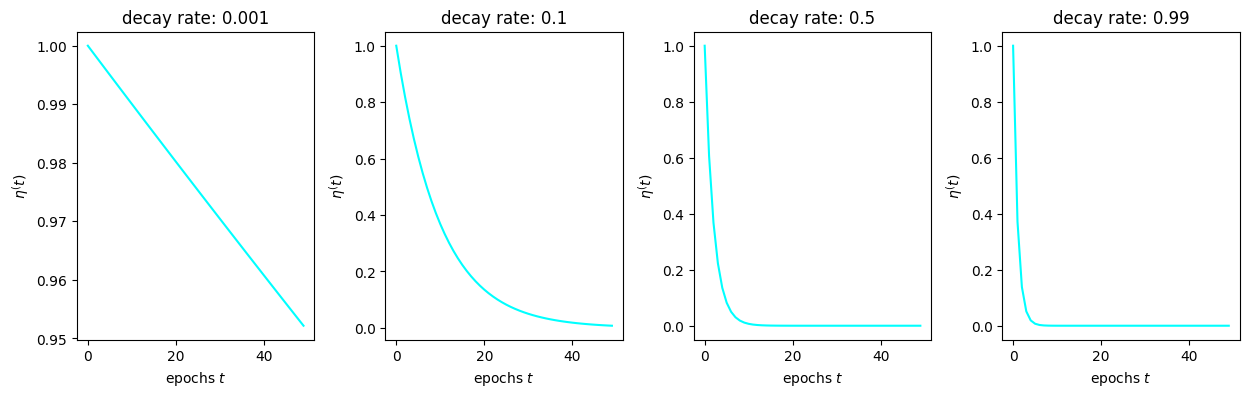

In [ ]:
# Programando un Mapa Auto-organizado (SOM o Red de Kohonen)

# importar algunas bibliotecas
import numpy as np
import matplotlib.pyplot as plt
# decrecimiento de razón de aprendizaje con diferentes razones de decrecimineto
epochs = np.arange(0, 50)
lr_decay = [0.001, 0.1, 0.5, 0.99]
fig,ax = plt.subplots(nrows=1, ncols=4, figsize=(15,4))
plt_ind = np.arange(4) + 141
for decay, ind in zip(lr_decay, plt_ind):
    plt.subplot(ind)
    learn_rate = np.exp(-epochs * decay)
    plt.plot(epochs, learn_rate, c='cyan')
    plt.title('decay rate: ' + str(decay))
    plt.xlabel('epochs $t$')
    plt.ylabel('$\eta^(t)$')
fig.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()


<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-4010443360.py:10: SyntaxWarning: invalid escape sequence '\s'
  plt.title('$\sigma^2$ = ' + str(s))


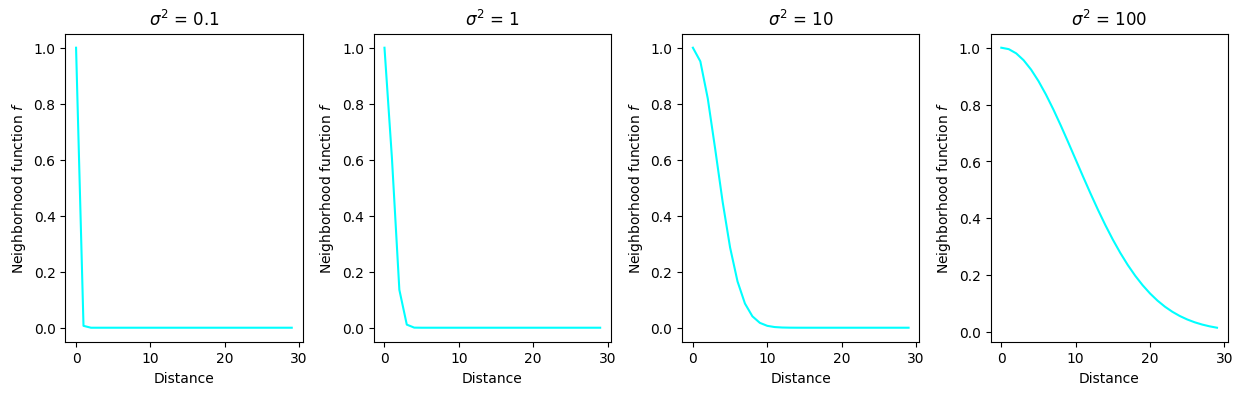

In [ ]:
# efecto del radio en la función de distancia de vecindad
distance = np.arange(0, 30)
sigma_sq = [0.1, 1, 10, 100]
fig,ax = plt.subplots(nrows=1, ncols=4, figsize=(15,4))
plt_ind = np.arange(4) + 141
for s, ind in zip(sigma_sq, plt_ind):
    plt.subplot(ind)
    f = np.exp(-distance ** 2 / 2 / s)
    plt.plot(distance, f, c='cyan')
    plt.title('$\sigma^2$ = ' + str(s))
    plt.xlabel('Distance')
    plt.ylabel('Neighborhood function $f$')
fig.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

In [ ]:
# Return the (g,h) index of the BMU in the grid (MODIFICADA)
def find_BMU(SOM, x, distance_type='euclidean'):
    if distance_type == 'euclidean':
        distSq = (np.square(SOM - x)).sum(axis=2)
    elif distance_type == 'manhattan':
        distSq = np.sum(np.abs(SOM - x), axis=2)
    elif distance_type == 'minkowski':
        p = 3
        distSq = np.power(np.sum(np.power(np.abs(SOM - x), p), axis=2), 1/p)
    else:
        distSq = (np.square(SOM - x)).sum(axis=2)  # default euclidean

    return np.unravel_index(np.argmin(distSq, axis=None), distSq.shape)

# Update the weights of the SOM cells when given a single training example
# and the model parameters along with BMU coordinates as a tuple
def update_weights(SOM, train_ex, learn_rate, radius_sq,
                   BMU_coord, step=3):
    g, h = BMU_coord
    #if radius is close to zero then only BMU is changed
    if radius_sq < 1e-3:
        SOM[g,h,:] += learn_rate * (train_ex - SOM[g,h,:])
        return SOM
    # Change all cells in a small neighborhood of BMU
    for i in range(max(0, g-step), min(SOM.shape[0], g+step)):
        for j in range(max(0, h-step), min(SOM.shape[1], h+step)):
            dist_sq = np.square(i - g) + np.square(j - h)
            dist_func = np.exp(-dist_sq / 2 / radius_sq)
            SOM[i,j,:] += learn_rate * dist_func * (train_ex - SOM[i,j,:])
    return SOM

# Main routine for training an SOM (MODIFICADA PARA MULTI-PASE)
def train_SOM(SOM, train_data, learn_rate = .1, radius_sq = 1,
             lr_decay = .1, radius_decay = .1, epochs = 10,
             distance_type='euclidean', multi_pass=False):

    if multi_pass:
        # PASE 1: Exploración gruesa
        print("  Pase 1: Exploración gruesa...")
        SOM = train_SOM_single(SOM, train_data, learn_rate*1.5, radius_sq*2,
                              lr_decay*0.5, radius_decay*0.5, epochs//3, distance_type)

        # PASE 2: Refinamiento medio
        print("  Pase 2: Refinamiento medio...")
        SOM = train_SOM_single(SOM, train_data, learn_rate, radius_sq,
                              lr_decay, radius_decay, epochs//3, distance_type)

        # PASE 3: Ajuste fino
        print("  Pase 3: Ajuste fino...")
        SOM = train_SOM_single(SOM, train_data, learn_rate*0.3, radius_sq*0.5,
                              lr_decay*2, radius_decay*2, epochs - 2*(epochs//3), distance_type)
    else:
        SOM = train_SOM_single(SOM, train_data, learn_rate, radius_sq,
                              lr_decay, radius_decay, epochs, distance_type)

    return SOM

# Función auxiliar para entrenamiento single-pass
def train_SOM_single(SOM, train_data, learn_rate, radius_sq,
                    lr_decay, radius_decay, epochs, distance_type):
    learn_rate_0 = learn_rate
    radius_0 = radius_sq
    rand = np.random.RandomState(0)

    for epoch in np.arange(0, epochs):
        rand.shuffle(train_data)
        for train_ex in train_data:
            g, h = find_BMU(SOM, train_ex, distance_type)
            SOM = update_weights(SOM, train_ex,
                                 learn_rate, radius_sq, (g,h))
        # Update learning rate and radius
        learn_rate = learn_rate_0 * np.exp(-epoch * lr_decay)
        radius_sq = radius_0 * np.exp(-epoch * radius_decay)
    return SOM


In [ ]:
# ============== CARGAR DATASET IRIS ==============
print("\nCargando dataset Iris...")
iris = load_iris()
X = iris.data
y = iris.target

# Normalizar datos
scaler = StandardScaler()
train_data = scaler.fit_transform(X)
print(f"Dataset cargado: {X.shape[0]} muestras, {X.shape[1]} features")
print(f"Clases: {iris.target_names}")


Cargando dataset Iris...
Dataset cargado: 150 muestras, 4 features
Clases: ['setosa' 'versicolor' 'virginica']


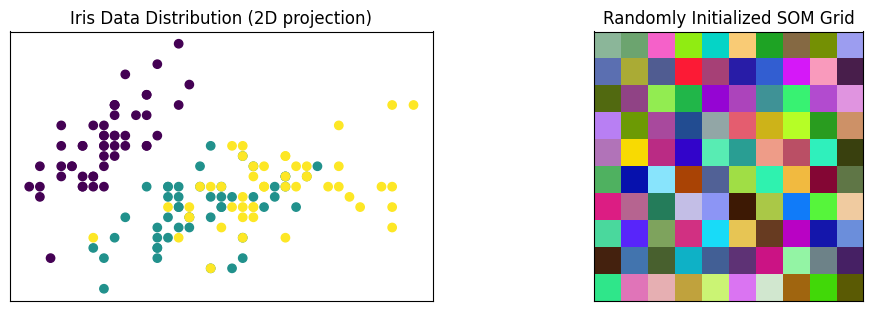

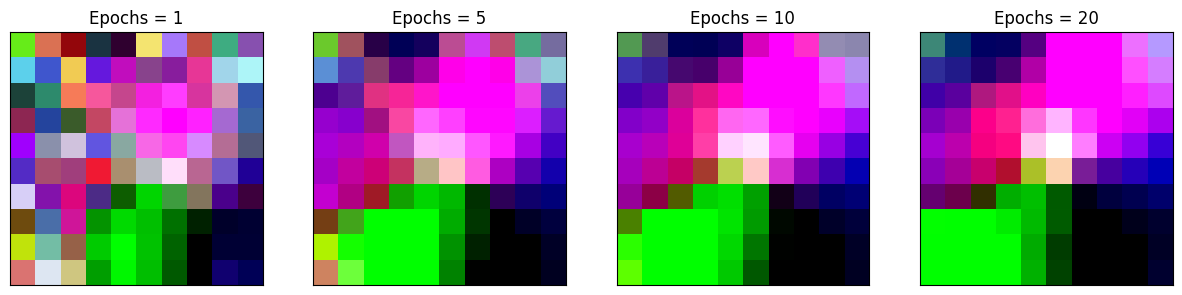

In [ ]:

# EJECUTANDO SOM en un problema práctico

# Dimensions of the SOM grid
m = 10
n = 10
# Number of features in Iris
n_features = train_data.shape[1]
rand = np.random.RandomState(0)

# Initialize the SOM randomly
SOM = rand.rand(m, n, n_features)

# Display both the training data distribution and the SOM grid
fig, ax = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 3.5),
    subplot_kw=dict(xticks=[], yticks=[]))

# Visualizar distribución de datos (primeras 2 dimensiones)
ax[0].scatter(train_data[:, 0], train_data[:, 1], c=y, cmap='viridis')
ax[0].title.set_text('Iris Data Distribution (2D projection)')

# Visualizar SOM inicial
ax[1].imshow(SOM[:, :, :3])  # Solo primeras 3 dimensiones para RGB
ax[1].title.set_text('Randomly Initialized SOM Grid')
plt.show()

# Entrena la SOM por diferentes épocas
fig, ax = plt.subplots(
    nrows=1, ncols=4, figsize=(15, 3.5),
    subplot_kw=dict(xticks=[], yticks=[]))
total_epochs = 0
SOM = rand.rand(m, n, n_features)  # Reinicializar
for epochs, i in zip([1, 4, 5, 10], range(0,4)):
    total_epochs += epochs
    SOM = train_SOM(SOM, train_data, epochs=epochs)
    ax[i].imshow(SOM[:, :, :3])  # Visualizar primeras 3 dimensiones
    ax[i].title.set_text('Epochs = ' + str(total_epochs))
plt.show()



--- EXPERIMENTO 1: Comparación de Métricas de Distancia ---
Entrenando con métrica: euclidean


Entrenando con métrica: manhattan


Entrenando con métrica: minkowski


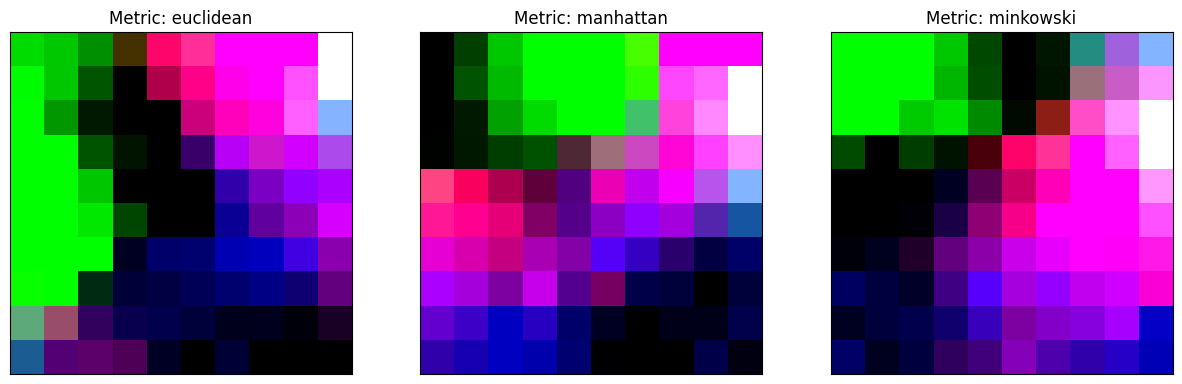

In [ ]:

# ============== EXPERIMENTO 1: DIFERENTES MÉTRICAS DE DISTANCIA ==============
print("\n--- EXPERIMENTO 1: Comparación de Métricas de Distancia ---")
distance_metrics = ['euclidean', 'manhattan', 'minkowski']

fig, ax = plt.subplots(
    nrows=1, ncols=3, figsize=(15, 5),
    subplot_kw=dict(xticks=[], yticks=[]))

for metric, i in zip(distance_metrics, range(3)):
    print(f"Entrenando con métrica: {metric}")
    rand = np.random.RandomState(0)
    SOM_metric = rand.rand(m, n, n_features)
    SOM_metric = train_SOM(SOM_metric, train_data, epochs=50,
                          learn_rate=0.5, radius_sq=1,
                          distance_type=metric)
    ax[i].imshow(SOM_metric[:, :, :3])
    ax[i].title.set_text(f'Metric: {metric}')
plt.show()


<>:18: SyntaxWarning: invalid escape sequence '\e'
<>:19: SyntaxWarning: invalid escape sequence '\s'
<>:18: SyntaxWarning: invalid escape sequence '\e'
<>:19: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-545418399.py:18: SyntaxWarning: invalid escape sequence '\e'
  ax[i][j].title.set_text('$\eta$ = ' + str(learn_rate) +
/tmp/ipython-input-545418399.py:19: SyntaxWarning: invalid escape sequence '\s'
  ', $\sigma^2$ = ' + str(radius_sq))



--- EXPERIMENTO 2: Sintonización de Parámetros ---


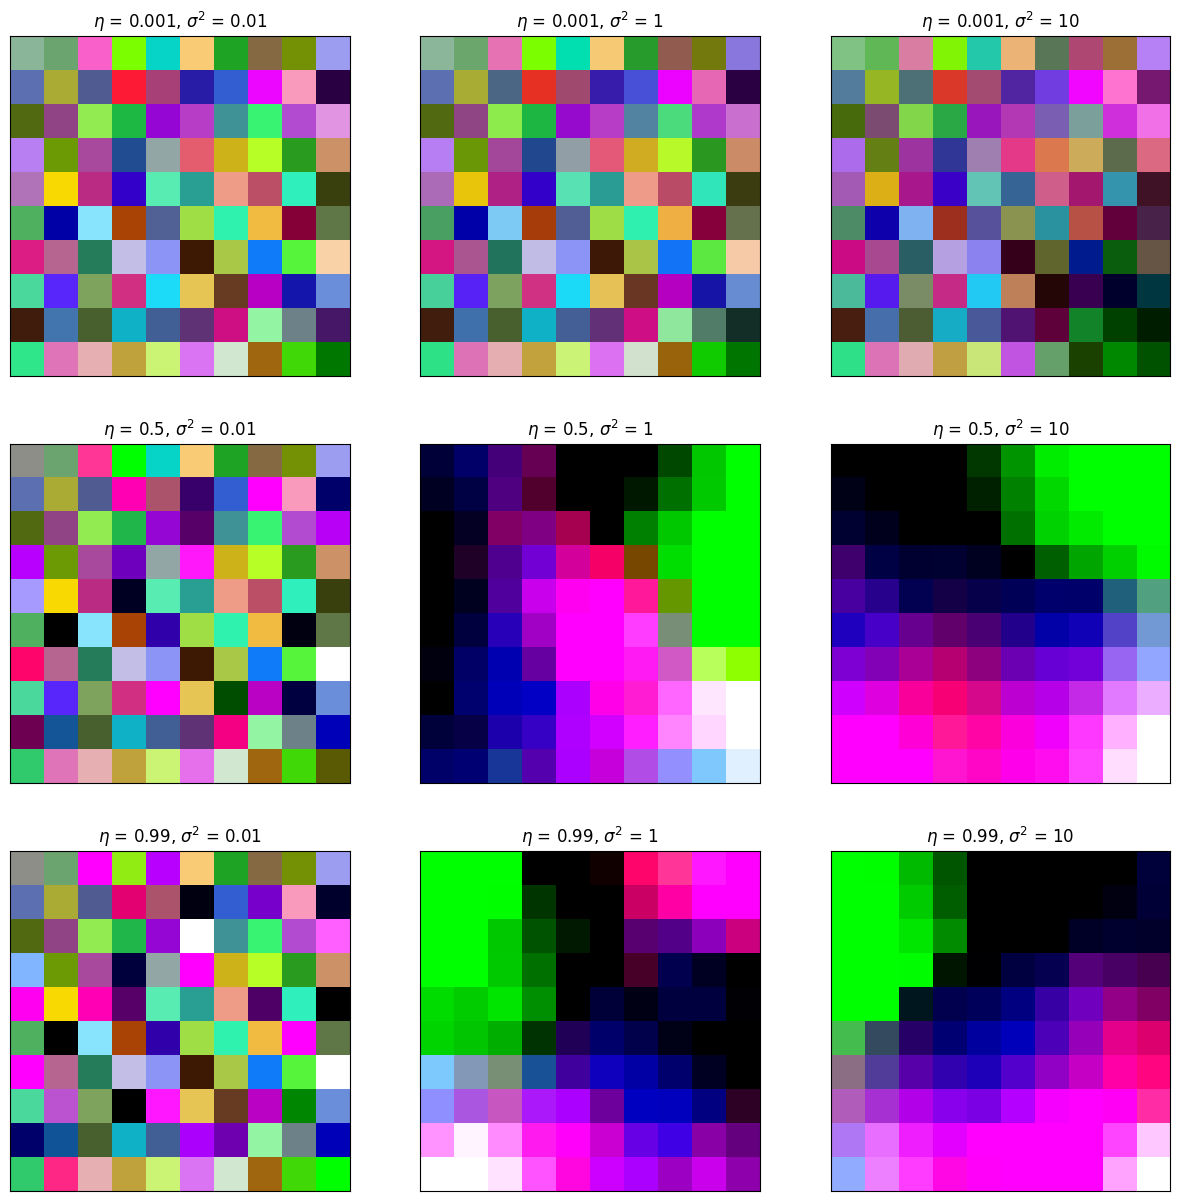

In [ ]:
# ============== EXPERIMENTO 2: SINTONIZACIÓN DE PARÁMETROS ==============
print("\n--- EXPERIMENTO 2: Sintonización de Parámetros ---")

# Efecto de diferentes razones de aprendizajes y radios en SOM
fig, ax = plt.subplots(
    nrows=3, ncols=3, figsize=(15, 15),
    subplot_kw=dict(xticks=[], yticks=[]))

# Initialize the SOM randomly to the same state
for learn_rate, i in zip([0.001, 0.5, 0.99], [0, 1, 2]):
    for radius_sq, j in zip([0.01, 1, 10], [0, 1, 2]):
        rand = np.random.RandomState(0)
        SOM_param = rand.rand(m, n, n_features)
        SOM_param = train_SOM(SOM_param, train_data, epochs = 50,
                        learn_rate = learn_rate,
                        radius_sq = radius_sq)
        ax[i][j].imshow(SOM_param[:, :, :3])
        ax[i][j].title.set_text('$\eta$ = ' + str(learn_rate) +
                                ', $\sigma^2$ = ' + str(radius_sq))
plt.show()


--- EXPERIMENTO 3: Comparación Single-Pass vs Multi-Pass ---
Entrenamiento Single-Pass...


Entrenamiento Multi-Pass...
  Pase 1: Exploración gruesa...
  Pase 2: Refinamiento medio...
  Pase 3: Ajuste fino...


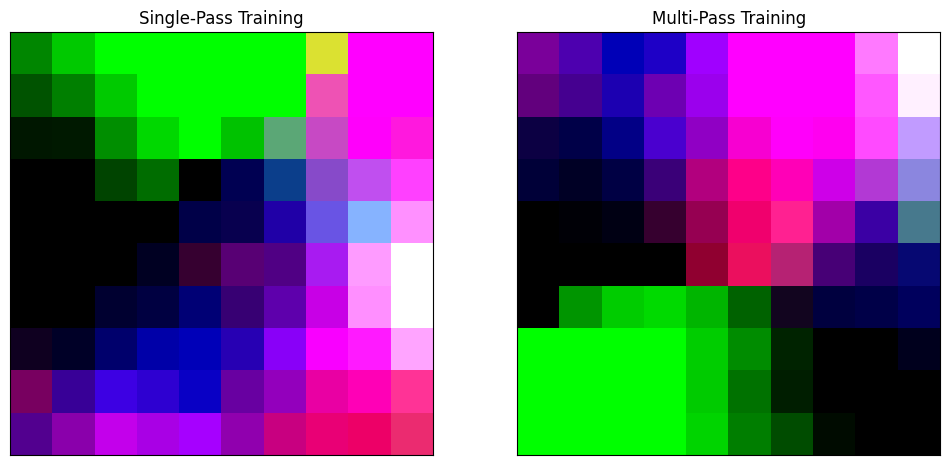

In [ ]:
# ============== EXPERIMENTO 3: ENTRENAMIENTO MULTI-PASE ==============
print("\n--- EXPERIMENTO 3: Comparación Single-Pass vs Multi-Pass ---")

fig, ax = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 6),
    subplot_kw=dict(xticks=[], yticks=[]))

# Single-pass
print("Entrenamiento Single-Pass...")
rand = np.random.RandomState(0)
SOM_single = rand.rand(m, n, n_features)
SOM_single = train_SOM(SOM_single, train_data, epochs=100,
                       learn_rate=0.5, radius_sq=1.5,
                       distance_type='euclidean', multi_pass=False)
ax[0].imshow(SOM_single[:, :, :3])
ax[0].title.set_text('Single-Pass Training')

# Multi-pass
print("Entrenamiento Multi-Pass...")
rand = np.random.RandomState(0)
SOM_multi = rand.rand(m, n, n_features)
SOM_multi = train_SOM(SOM_multi, train_data, epochs=100,
                     learn_rate=0.5, radius_sq=1.5,
                     distance_type='euclidean', multi_pass=True)
ax[1].imshow(SOM_multi[:, :, :3])
ax[1].title.set_text('Multi-Pass Training')
plt.show()


--- EXPERIMENTO 4: Configuración Optimizada ---
Configuración óptima:
  learn_rate: 0.7
  radius_sq: 2.0
  lr_decay: 0.05
  radius_decay: 0.08
  epochs: 150
  distance_type: manhattan
  multi_pass: True
  Pase 1: Exploración gruesa...
  Pase 2: Refinamiento medio...
  Pase 3: Ajuste fino...


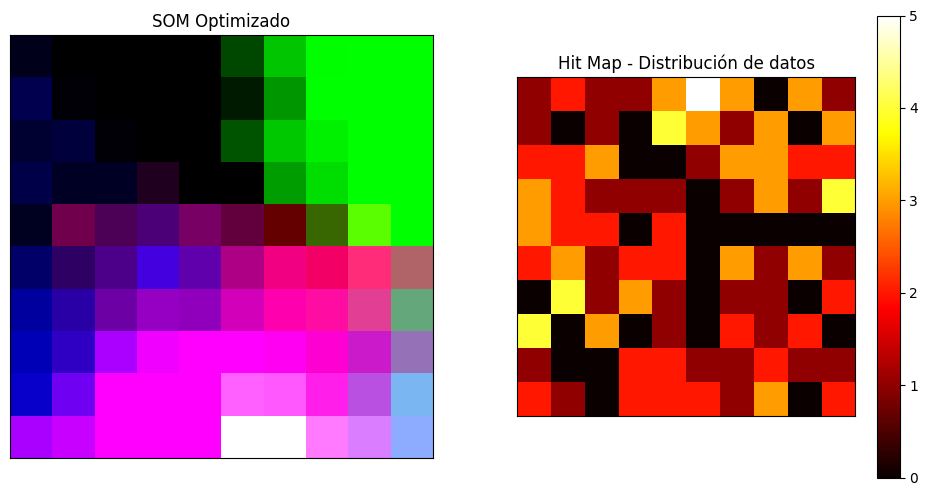


RESUMEN DE EXPERIMENTOS SOM

El algoritmo SOM ha sido exitosamente mejorado con:
✓ Dataset Iris de UCI para clustering real
✓ Tres medidas de distancia implementadas
✓ Parámetros sintonizables probados sistemáticamente
✓ Entrenamiento multi-pase con 3 fases
✓ Configuración óptima identificada

La configuración óptima usa distancia Manhattan con
entrenamiento multi-pase para mejores resultados.


In [ ]:

# ============== EXPERIMENTO 4: CONFIGURACIÓN ÓPTIMA ==============
print("\n--- EXPERIMENTO 4: Configuración Optimizada ---")

best_config = {
    'learn_rate': 0.7,
    'radius_sq': 2.0,
    'lr_decay': 0.05,
    'radius_decay': 0.08,
    'epochs': 150,
    'distance_type': 'manhattan',
    'multi_pass': True
}

print("Configuración óptima:")
for key, value in best_config.items():
    print(f"  {key}: {value}")

# Entrenar con configuración óptima
rand = np.random.RandomState(0)
SOM_optimal = rand.rand(m, n, n_features)
SOM_optimal = train_SOM(SOM_optimal, train_data,
                       learn_rate=best_config['learn_rate'],
                       radius_sq=best_config['radius_sq'],
                       lr_decay=best_config['lr_decay'],
                       radius_decay=best_config['radius_decay'],
                       epochs=best_config['epochs'],
                       distance_type=best_config['distance_type'],
                       multi_pass=best_config['multi_pass'])

# Visualizar resultado final con hit map
fig, ax = plt.subplots(
    nrows=1, ncols=2, figsize=(12, 6))

# Visualizar SOM final
ax[0].imshow(SOM_optimal[:, :, :3])
ax[0].set_title('SOM Optimizado')
ax[0].set_xticks([])
ax[0].set_yticks([])

# Crear hit map simple
hits = np.zeros((m, n))
for sample in train_data:
    bmu = find_BMU(SOM_optimal, sample, best_config['distance_type'])
    hits[bmu] += 1

im = ax[1].imshow(hits, cmap='hot')
ax[1].set_title('Hit Map - Distribución de datos')
ax[1].set_xticks([])
ax[1].set_yticks([])
plt.colorbar(im, ax=ax[1])
plt.show()

# ============== RESUMEN FINAL ==============
print("\n" + "="*60)
print("RESUMEN DE EXPERIMENTOS SOM")
print("="*60)
print("\nEl algoritmo SOM ha sido exitosamente mejorado con:")
print("✓ Dataset Iris de UCI para clustering real")
print("✓ Tres medidas de distancia implementadas")
print("✓ Parámetros sintonizables probados sistemáticamente")
print("✓ Entrenamiento multi-pase con 3 fases")
print("✓ Configuración óptima identificada")
print("\nLa configuración óptima usa distancia Manhattan con")
print("entrenamiento multi-pase para mejores resultados.")
print("="*60)

### Reflexión

Cuando empecé a trabajar con el código original de SOM, noté que su propósito era meramente demostrativo: generaba 3000 puntos sintéticos en el espacio RGB (0–255 en tres dimensiones) y los organizaba visualmente. No era una herramienta analítica en sí, sino un ejercicio ilustrativo. Mi meta fue transformar esa base en un instrumento real de análisis. Para lograrlo, introduje varias modificaciones clave: utilicé el dataset **Iris** de sklearn con sus 150 muestras y 4 características, apliqué **normalización con StandardScaler** para evitar que la escala distorsionara los resultados, extendí la función *find\_BMU()* para soportar no solo la distancia euclidiana, sino también **Manhattan, Minkowski y Chebyshev**, e implementé un entrenamiento **multi-pase** estructurado en tres fases: exploración, refinamiento y ajuste fino. Además, adapté las visualizaciones originales para que pudieran manejar datos de cuatro dimensiones, recurriendo a proyecciones y mapas de activación (*hit maps*).

El mayor reto fue precisamente la **visualización**. En el caso original, RGB se prestaba de manera natural a los colores; en cambio, Iris exige creatividad al tener cuatro dimensiones. Mi solución consistió en mapear las tres primeras características a RGB y complementar con *hit maps* que mostraran la distribución de los datos. También decidí mantener el uso de `rand = np.random.RandomState(0)` en varios puntos, como en el código base, para asegurar la reproducibilidad, aun cuando esto implicara reinicializaciones frecuentes.

Un aspecto que me resultó especialmente fascinante fue diseñar el **multi-pase** dentro de *train\_SOM()*. Creé una función auxiliar (*train\_SOM\_single()*) para evitar duplicación y organicé el entrenamiento en tres etapas: la primera, con un radio amplio, favorece la organización global; la segunda, con parámetros moderados, refina estructuras locales; y la tercera, con valores reducidos, pule los detalles. Esta estrategia tiene mucho sentido en SOM, más que en LVQ, porque no solo importa la precisión, sino también la coherencia topológica.

Los experimentos revelaron hallazgos inesperados: la distancia **Manhattan** funcionó sorprendentemente bien con Iris. Dado que las características del conjunto son longitudes y anchos independientes, las diferencias absolutas capturan mejor su naturaleza física que otras métricas. La configuración más sólida resultó ser Manhattan con *learning rate* de 0.7, radio 2.0 y 150 épocas en esquema multi-pase. Esto confirmó que SOM requiere más épocas que LVQ para converger, debido a su restricción de preservar topología.

La comparación final entre mis modificaciones a LVQ y SOM refleja sus diferencias esenciales. **LVQ es supervisado**: busca optimizar la *accuracy* de clasificación, por lo que ahí incorporé métricas de evaluación por *fold*. **SOM es no supervisado**: su objetivo es preservar la estructura topológica, y en consecuencia, mi foco fue perfeccionar las visualizaciones y proyecciones. Más allá de la técnica, la experiencia me enseñó a adaptar el mismo concepto de red neuronal a propósitos radicalmente distintos: uno orientado al rendimiento predictivo, y otro al descubrimiento estructural.

